In [178]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyodbc

In [179]:
conn = pyodbc.connect(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    "SERVER=localhost\\SQLEXPRESS;"
    "DATABASE=MotoDB;"
    "Trusted_Connection=yes;"
)

In [180]:
clean_df = pd.read_sql("SELECT * FROM MotoDB.dbo.VehicleSales", conn)

C:\Users\DELL\AppData\Local\Temp\ipykernel_27864\32298433.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  clean_df = pd.read_sql("SELECT * FROM MotoDB.dbo.VehicleSales", conn)


In [181]:
clean_df

,Id,Year,Make,Model,Trim,Body,Transmission,VIN,State,ConditionValue,Odometer,Color,Interior,Seller,MMR,SellingPrice,SaleDate
0,2,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,2014-12-16 04:30:00
1,3,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,2014-12-16 04:30:00
2,4,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,2015-01-14 20:30:00
3,5,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,2015-01-28 20:30:00
4,6,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,2014-12-18 04:30:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
558832,558834,2015,Kia,K900,Luxury,Sedan,NaN,knalw4d4xf6019304,in,45.0,18255.0,silver,black,avis corporation,35300.0,33000.0,2015-07-09 00:00:00
558833,558835,2012,Ram,2500,Power Wagon,Crew Cab,automatic,3c6td5et6cg112407,wa,5.0,54393.0,white,black,i -5 uhlmann rv,30200.0,30800.0,2015-07-08 02:30:00
558834,558836,2012,BMW,X5,xDrive35d,SUV,automatic,5uxzw0c58cl668465,ca,48.0,50561.0,black,black,financial services remarketing (lease),29800.0,34000.0,2015-07-08 02:30:00
558835,558837,2015,Nissan,Altima,2.5 S,sedan,automatic,1n4al3ap0fc216050,ga,38.0,16658.0,white,black,enterprise vehicle exchange / tra / rental / t...,15100.0,11100.0,2015-07-08 23:45:00


In [182]:
raw_df = pd.read_sql("SELECT * FROM MotoDB.dbo.VehicleSales", conn)
clean_df = raw_df.copy()

C:\Users\DELL\AppData\Local\Temp\ipykernel_27864\392970817.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  raw_df = pd.read_sql("SELECT * FROM MotoDB.dbo.VehicleSales", conn)


In [183]:
clean_df[clean_df.isna()]

,Id,Year,Make,Model,Trim,Body,Transmission,VIN,State,ConditionValue,Odometer,Color,Interior,Seller,MMR,SellingPrice,SaleDate
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
558832,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
558833,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
558834,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
558835,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT


In [184]:
clean_df.isnull().sum()


Id                    0
Year                  0
Make              10301
Model             10399
Trim              10651
Body              13195
Transmission      65352
VIN                   4
State                 0
ConditionValue    11820
Odometer             94
Color               749
Interior            749
Seller                0
MMR                  38
SellingPrice         12
SaleDate             38
dtype: int64

In [185]:
missing_percentage = clean_df.isnull().mean() * 100
missing_percentage.sort_values(ascending=False)

Transmission      11.694287
Body               2.361154
ConditionValue     2.115107
Trim               1.905922
Model              1.860829
Make               1.843292
Color              0.134028
Interior           0.134028
Odometer           0.016821
SaleDate           0.006800
MMR                0.006800
SellingPrice       0.002147
VIN                0.000716
Id                 0.000000
Year               0.000000
State              0.000000
Seller             0.000000
dtype: float64

In [186]:
numeric_cols = [
    "ConditionValue",
    "Odometer",
    "MMR",
    "SellingPrice"
]

for col in numeric_cols:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

In [187]:
categorical_cols = [
    "Make",
    "Model",
    "Trim",
    "Body",
    "Color",
    "Transmission",
    "VIN",
    "Interior"
]
for col in categorical_cols:
    clean_df[col] = clean_df[col].fillna("Unknown")


In [188]:
clean_df = clean_df.dropna(subset=["SaleDate"])

In [189]:
clean_df.duplicated().sum()

np.int64(0)

In [190]:
clean_df[["Year", "ConditionValue", "Odometer", "MMR", "SellingPrice"]].describe()

,Year,ConditionValue,Odometer,MMR,SellingPrice
count,558799.000000,558799.000000,558799.000000,558799.000000,558799.000000
mean,2010.038633,30.763892,68321.127182,13769.377495,13611.356296
std,3.966830,13.275258,53394.048920,9679.967174,9749.728196
min,1982.000000,1.000000,1.000000,25.000000,1.000000
25%,2007.000000,24.000000,28378.000000,7100.000000,6900.000000
50%,2012.000000,35.000000,52254.000000,12250.000000,12100.000000
75%,2013.000000,41.000000,99105.500000,18300.000000,18200.000000
max,2015.000000,49.000000,999999.000000,182000.000000,230000.000000


In [191]:
clean_df[clean_df["Odometer"] == 999999]

,Id,Year,Make,Model,Trim,Body,Transmission,VIN,State,ConditionValue,Odometer,Color,Interior,Seller,MMR,SellingPrice,SaleDate
275,277,2013,Hyundai,Elantra Coupe,GS,Elantra Coupe,automatic,kmhdh6ae8du017422,ca,1.0,999999.0,blue,gray,hyundai motor finance,8025.0,2500.0,2015-01-26 20:00:00
4626,4628,2003,Chevrolet,Silverado 1500,LS,Extended Cab,automatic,1gcec19v43e225059,ca,2.0,999999.0,gray,gray,800 loan mart,1425.0,700.0,2014-12-16 05:00:00
13317,13319,2009,Chevrolet,Cobalt,LT,Coupe,automatic,1g1at18h797165360,tx,35.0,999999.0,white,gray,mei finance,3375.0,400.0,2014-12-18 06:00:00
13480,13482,2009,Dodge,Charger,Base,Sedan,automatic,2b3ka43d49h578284,il,1.0,999999.0,black,gray,santander consumer,3850.0,1700.0,2014-12-23 05:00:00
13568,13570,2009,Dodge,Charger,Base,Sedan,automatic,2b3ka43dx9h521300,tx,1.0,999999.0,blue,black,santander consumer,4150.0,5500.0,2015-01-08 06:10:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
489833,489835,2008,Chrysler,300,Touring,sedan,automatic,2c3la53g88h288734,ca,27.0,999999.0,silver,beige,chrysler capital,4325.0,1200.0,2015-06-01 23:00:00
490461,490463,2002,Ford,Expedition,Eddie Bauer,suv,automatic,1fmru17l72la49923,tx,2.0,999999.0,black,gray,titlemax/leon valley tx1,600.0,600.0,2015-06-02 20:20:00
501478,501480,2011,Volkswagen,Jetta,SEL,sedan,Unknown,3vwlx7aj1bm387406,tx,1.0,999999.0,white,tan,santander consumer,8600.0,1100.0,2015-06-02 22:30:00
513219,513221,2006,Ford,Taurus,SEL,sedan,automatic,1fafp56u06a197709,oh,19.0,999999.0,gray,gray,car now acceptance co/columbus,175.0,400.0,2015-06-10 19:00:00


In [192]:
clean_df[clean_df["MMR"] < 100][
    ["Year", "Make", "Model", "Trim", "MMR"]
]

,Year,Make,Model,Trim,MMR
4952,2001,Chrysler,Sebring,LX,25.0
7446,2003,Chevrolet,Astro Cargo,Base,25.0
22116,2005,Chevrolet,Silverado 3500,LS,75.0
22243,2005,Chrysler,Sebring,Touring,50.0
25325,2003,Buick,Regal,LS,25.0
...,...,...,...,...,...
542414,2001,Buick,LeSabre,Limited,50.0
547212,1994,Mercedes-Benz,E-Class,E420,75.0
556431,1998,Oldsmobile,Bravada,Base,75.0
557852,2000,Buick,LeSabre,Limited,25.0


In [193]:
clean_df[clean_df["SellingPrice"] < 100][
    ["Year", "Make", "Model", "Trim", "SellingPrice"]
]

,Year,Make,Model,Trim,SellingPrice
7566,2002,Ford,F-350 Super Duty,XLT,1.0
48453,2003,Mercedes-Benz,E-Class,E500,1.0
293223,2014,Ford,E-Series Van,E-250,1.0
348252,1995,Isuzu,Rodeo,LS,1.0


In [194]:
clean_df[clean_df["SellingPrice"] <= 100][
    ["Year", "Make", "Model", "Trim", "MMR", "SellingPrice"]
]

,Year,Make,Model,Trim,MMR,SellingPrice
5184,1997,ford,explorer,awd xlt,500.0,100.0
7566,2002,Ford,F-350 Super Duty,XLT,7850.0,1.0
25588,2003,Chevrolet,Malibu,LS,950.0,100.0
30275,1993,Unknown,Unknown,Unknown,1775.0,100.0
48453,2003,Mercedes-Benz,E-Class,E500,7325.0,1.0
196184,2004,Pontiac,Montana,Base,1700.0,100.0
205309,2002,Chrysler,Sebring,GTC,1325.0,100.0
227773,2009,Unknown,Unknown,Unknown,3825.0,100.0
241038,1997,Mitsubishi,Galant,ES,325.0,100.0
281158,2003,Nissan,Altima,2.5 SL,2950.0,100.0


In [195]:
clean_df[clean_df["SellingPrice"] == 1][
    ["Year", "Make", "Model", "Trim", "Odometer", "MMR", "SellingPrice"]
]

,Year,Make,Model,Trim,Odometer,MMR,SellingPrice
7566,2002,Ford,F-350 Super Duty,XLT,52254.0,7850.0,1.0
48453,2003,Mercedes-Benz,E-Class,E500,1.0,7325.0,1.0
293223,2014,Ford,E-Series Van,E-250,31886.0,20800.0,1.0
348252,1995,Isuzu,Rodeo,LS,254132.0,375.0,1.0


In [196]:
clean_df["SellingPrice"].value_counts().sort_index().head(20)

SellingPrice
1.0         4
100.0      19
125.0       1
150.0      21
175.0      10
200.0     196
225.0     105
250.0     281
275.0     124
300.0    1282
325.0     221
350.0     725
375.0     143
385.0       1
400.0    1579
420.0       1
425.0      98
450.0     480
475.0      46
500.0    1732
Name: count, dtype: int64

In [197]:
clean_df["SellingPrice"].describe()

count    558799.000000
mean      13611.356296
std        9749.728196
min           1.000000
25%        6900.000000
50%       12100.000000
75%       18200.000000
max      230000.000000
Name: SellingPrice, dtype: float64

In [198]:
print("SellingPrice = 1:", (clean_df["SellingPrice"] == 1).sum())
print("Odometer = 999999:", (clean_df["Odometer"] == 999999).sum())

SellingPrice = 1: 4
Odometer = 999999: 72


In [199]:
clean_df["SellingPrice_1_flag"] = clean_df["SellingPrice"].eq(1)
clean_df["Odometer_999999_flag"] = clean_df["Odometer"].eq(999999)

In [200]:
clean_df["SellingPrice"].isnull().sum()

np.int64(0)

In [201]:
clean_df[clean_df["Odometer"] == 999999][
    ["Year", "Make", "Model", "Trim", "Odometer", "MMR", "SellingPrice"]
].head(10)

,Year,Make,Model,Trim,Odometer,MMR,SellingPrice
275,2013,Hyundai,Elantra Coupe,GS,999999.0,8025.0,2500.0
4626,2003,Chevrolet,Silverado 1500,LS,999999.0,1425.0,700.0
13317,2009,Chevrolet,Cobalt,LT,999999.0,3375.0,400.0
13480,2009,Dodge,Charger,Base,999999.0,3850.0,1700.0
13568,2009,Dodge,Charger,Base,999999.0,4150.0,5500.0
20838,2006,Kia,Amanti,Base,999999.0,900.0,800.0
38465,2012,Nissan,Altima,2.5 S,999999.0,7375.0,800.0
39178,2009,Dodge,Grand Caravan,SXT,999999.0,3325.0,1500.0
40121,2006,Ford,F-150,King Ranch,999999.0,7500.0,3600.0
55492,2005,Nissan,Quest,3.5 SE,999999.0,2250.0,2600.0


In [202]:
import numpy as np
clean_df.loc[
    clean_df["Odometer"] == 999999,
    "Odometer"
] = np.nan

In [203]:
clean_df["Odometer"].isnull().sum()

np.int64(72)

In [204]:
(clean_df["Odometer"] == 999999).sum()

np.int64(0)

In [205]:
clean_df.describe()

,Id,Year,ConditionValue,Odometer,MMR,SellingPrice,SaleDate
count,558799.000000,558799.000000,558799.000000,558727.000000,558799.000000,558799.000000,558799
mean,279406.887006,2010.038633,30.763892,68201.067104,13769.377495,13611.356296,2015-03-06 00:09:10.521386
min,2.000000,1982.000000,1.000000,1.000000,25.000000,1.000000,2014-01-01 01:15:00
25%,139701.500000,2007.000000,24.000000,28375.000000,7100.000000,6900.000000,2015-01-20 18:00:00
50%,279401.000000,2012.000000,35.000000,52254.000000,12250.000000,12100.000000,2015-02-12 19:20:00
75%,419104.500000,2013.000000,41.000000,99089.500000,18300.000000,18200.000000,2015-05-21 19:00:00
max,558838.000000,2015.000000,49.000000,980113.000000,182000.000000,230000.000000,2015-07-20 19:30:00
std,161319.516758,3.966830,13.275258,52339.468006,9679.967174,9749.728196,NaN


In [206]:
clean_df["ConditionValue"].value_counts().sort_index()

ConditionValue
1.0      7364
2.0     20790
3.0     10802
4.0     19922
5.0     11222
11.0       87
12.0       95
13.0       82
14.0      134
15.0      144
16.0      178
17.0      243
18.0      323
19.0    42276
21.0     9199
22.0     6057
23.0     8188
24.0     9326
25.0    12559
26.0    11911
27.0    16350
28.0    19177
29.0    18928
31.0     9222
32.0     9962
33.0    10619
34.0    17397
35.0    38544
36.0    23144
37.0    25938
38.0    18723
39.0    19920
41.0    23073
42.0    24328
43.0    24937
44.0    25514
45.0    12313
46.0    12634
47.0    11363
48.0    12712
49.0    13099
Name: count, dtype: int64

In [207]:
clean_df["Body"].value_counts(dropna=False)

Body
Sedan          199429
SUV            119292
sedan           41903
suv             24552
Hatchback       21380
                ...  
CTS-V Wagon         1
Ram Van             1
g37 coupe           1
cab plus 4          1
cts wagon           1
Name: count, Length: 87, dtype: int64

In [208]:
clean_df["Body"] = clean_df["Body"].str.strip().str.title()

In [209]:
clean_df["Transmission"].value_counts(dropna=False)

Transmission
automatic    475904
Unknown       65351
manual        17544
Name: count, dtype: int64

In [210]:
clean_df["Model"].value_counts(dropna=False)

Model
Altima                19349
F-150                 14479
Fusion                12945
Camry                 12545
Escape                11861
                      ...  
Grand Cherokee SRT        1
Q3                        1
360                       1
TLX                       1
458 Italia                1
Name: count, Length: 974, dtype: int64

In [211]:
clean_df["Model"].str.strip().str.lower().value_counts().head(20)

Model
altima            19349
f-150             14479
fusion            12945
camry             12549
escape            11893
unknown           10399
focus             10399
accord             9155
3 series           8204
impala             7957
grand caravan      7941
explorer           7781
civic              7440
g sedan            7417
corolla            7360
malibu             7146
sonata             6912
maxima             6611
silverado 1500     6362
cruze              6349
Name: count, dtype: int64

In [212]:
clean_df["Transmission"].value_counts(dropna=False)

Transmission
automatic    475904
Unknown       65351
manual        17544
Name: count, dtype: int64

In [213]:
clean_df["Make"].value_counts(dropna=False)

Make
Ford          93553
Chevrolet     60197
Nissan        53946
Toyota        39871
Dodge         30708
              ...  
chev truck        1
ford tk           1
airstream         1
dot               1
Lotus             1
Name: count, Length: 97, dtype: int64

In [214]:
clean_df["VIN"].value_counts(dropna=False)

VIN
wbanv13588cz57827    5
5uxfe43579l274932    4
5n1ar1nn2bc632869    4
wp0ca2988xu629622    4
1ftfw1cv5afb30053    4
                    ..
knalw4d4xf6019304    1
3c6td5et6cg112407    1
5uxzw0c58cl668465    1
1n4al3ap0fc216050    1
1ftfw1et2eke87277    1
Name: count, Length: 550284, dtype: int64

In [215]:
clean_df["VIN"].str.len().value_counts().sort_index()

VIN
17    558799
Name: count, dtype: int64

In [216]:
clean_df["VIN"].value_counts(dropna=False).head(20)

VIN
wbanv13588cz57827    5
5uxfe43579l274932    4
5n1ar1nn2bc632869    4
wp0ca2988xu629622    4
1ftfw1cv5afb30053    4
wddgf56x78f009940    4
trusc28n241022003    4
1c4pjlak9cw151871    3
1ftex1em5bfc39949    3
2d4rn4dg2br731466    3
2fabp7bv5ax113795    3
1ftex1cw2ake55543    3
jn1az44e19m402478    3
2c3ka43r78h186722    3
wddng71x47a041960    3
1d4pt4gk4bw600835    3
2c4rdgeg8er151143    3
wmwzc5c52bwl55400    3
jn8az1mw2bw180049    3
2fmdk3jc5abb53233    3
Name: count, dtype: int64

In [217]:
clean_df["VIN"].isna().sum()

np.int64(0)

In [218]:
clean_df["VIN"].nunique()

550284

In [219]:
clean_df["State"].value_counts(dropna=False)

State
fl    82945
ca    73148
pa    53907
tx    45913
ga    34750
nj    27784
il    23478
nc    21845
oh    21575
tn    20895
mo    16013
mi    15511
nv    12685
va    12025
md    11157
wi     9851
mn     9429
az     8740
co     7775
wa     7416
ma     6729
ny     5699
in     4325
sc     4251
ne     4013
on     3442
pr     2725
la     2191
ms     1851
ut     1836
qc     1245
hi     1237
or     1155
ab      928
nm      171
ok       72
ns       61
al       26
Name: count, dtype: int64

In [220]:
clean_df["State"].unique()

<StringArray>
['ca', 'tx', 'pa', 'mn', 'az', 'wi', 'tn', 'md', 'fl', 'ne', 'nj', 'nv', 'oh',
 'mi', 'ga', 'va', 'sc', 'nc', 'in', 'il', 'co', 'ut', 'mo', 'ny', 'ma', 'pr',
 'or', 'la', 'wa', 'hi', 'qc', 'ab', 'on', 'ok', 'ms', 'nm', 'al', 'ns']
Length: 38, dtype: str

In [221]:
clean_df[clean_df["State"].isin(["pr", "qc", "ab", "on", "ns"])]["State"].value_counts()

State
on    3442
pr    2725
qc    1245
ab     928
ns      61
Name: count, dtype: int64

In [222]:
clean_df["Trim"].value_counts(dropna=False)

Trim
Base                  55815
SE                    43646
LX                    20756
Limited               18367
LT                    16915
                      ...  
S E-Hybrid                1
4.2 quattro Spyder        1
pure                      1
EWB                       1
Power Wagon               1
Name: count, Length: 1963, dtype: int64

In [223]:
clean_df["Color"].value_counts(dropna=False)

Color
black        110969
white        106670
silver        83385
gray          82854
blue          51138
red           43569
—             24685
green         11382
gold          11342
beige          9222
burgundy       8972
brown          6717
orange         2078
purple         1561
off-white      1449
yellow         1285
Unknown         749
charcoal        479
turquoise       236
pink             42
lime             15
Name: count, dtype: int64

In [224]:
clean_df["Color"] = clean_df["Color"].str.strip().str.title()
clean_df["Interior"] = clean_df["Interior"].str.strip().str.title()

In [225]:
clean_df["Color"] = clean_df["Color"].replace("—", np.nan)

In [226]:
clean_df["Color"]=clean_df["Color"].fillna("Unknown")

In [227]:
clean_df["Color"].value_counts(dropna=False)

Color
Black        110969
White        106670
Silver        83385
Gray          82854
Blue          51138
Red           43569
Unknown       25434
Green         11382
Gold          11342
Beige          9222
Burgundy       8972
Brown          6717
Orange         2078
Purple         1561
Off-White      1449
Yellow         1285
Charcoal        479
Turquoise       236
Pink             42
Lime             15
Name: count, dtype: int64

In [228]:
clean_df["Interior"].value_counts(dropna=False)

Interior
Black        244320
Gray         178572
Beige         59758
Tan           44093
—             17075
Brown          8640
Red            1359
Blue           1138
Silver         1099
Unknown         749
Off-White       480
Purple          339
Gold            324
White           252
Green           245
Burgundy        191
Orange          145
Yellow           20
Name: count, dtype: int64

In [229]:
clean_df["Interior"]=clean_df["Interior"].replace("—", np.nan)

In [230]:
clean_df["Interior"]=clean_df["Interior"].fillna("Unknown")

In [231]:
clean_df["Interior"].value_counts(dropna=False)

Interior
Black        244320
Gray         178572
Beige         59758
Tan           44093
Unknown       17824
Brown          8640
Red            1359
Blue           1138
Silver         1099
Off-White       480
Purple          339
Gold            324
White           252
Green           245
Burgundy        191
Orange          145
Yellow           20
Name: count, dtype: int64

In [232]:
clean_df["Seller"].value_counts(dropna=False)

Seller
nissan-infiniti lt                 19693
ford motor credit company llc      19162
the hertz corporation              18299
santander consumer                 15285
avis corporation                   12540
                                   ...  
magnum motors llc                      1
a-1 auto group llc                     1
g brothers auto brokers inc            1
alternative financial group inc        1
i -5 uhlmann rv                        1
Name: count, Length: 14260, dtype: int64

In [233]:
clean_df["Seller"].str.strip().str.lower().value_counts().head(30)

Seller
nissan-infiniti lt                        19693
ford motor credit company llc             19162
the hertz corporation                     18299
santander consumer                        15285
avis corporation                          12540
nissan infiniti lt                         9962
wells fargo dealer services                8796
tdaf remarketing                           7209
enterprise veh exchange/rental             6853
ge fleet services for itself/servicer      6692
hyundai motor finance                      6660
jpmorgan chase bank n.a.                   6235
ahfc/honda lease trust/hvt  inc. eot       6069
financial services remarketing (lease)     6009
mercedes-benz financial services           5658
chrysler capital                           5577
gm financial                               5270
r hollenshead auto sales inc               5021
credit acceptance corp/vrs/southfield      4767
dt credit corporation                      4721
avis budget group                

In [234]:
id="r7k3mp"
clean_df["Seller"].str.replace("-", " ", regex=False).str.strip().str.lower().value_counts().head(30)

Seller
nissan infiniti lt                        29655
ford motor credit company llc             19162
the hertz corporation                     18299
santander consumer                        15285
avis corporation                          12540
wells fargo dealer services                8796
tdaf remarketing                           7209
enterprise veh exchange/rental             6853
ge fleet services for itself/servicer      6692
hyundai motor finance                      6660
jpmorgan chase bank n.a.                   6235
ahfc/honda lease trust/hvt  inc. eot       6069
financial services remarketing (lease)     6009
mercedes benz financial services           5658
chrysler capital                           5577
gm financial                               5270
r hollenshead auto sales inc               5021
credit acceptance corp/vrs/southfield      4767
dt credit corporation                      4721
avis budget group                          4638
kia motors america  inc          

In [235]:
Q1 = clean_df["SellingPrice"].quantile(0.25)
Q3 = clean_df["SellingPrice"].quantile(0.75)

print("Q1:", Q1)
print("Q3:", Q3)

Q1: 6900.0
Q3: 18200.0


In [236]:
IQR = Q3 - Q1

print("IQR:", IQR)

IQR: 11300.0


In [237]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -10050.0
Upper Bound: 35150.0


In [238]:
outliers = clean_df[
    (clean_df["SellingPrice"] < lower_bound) |
    (clean_df["SellingPrice"] > upper_bound)
]

print("Number of outliers:", len(outliers))

Number of outliers: 16354


In [239]:
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 6900.0
Q3: 18200.0
IQR: 11300.0
Lower Bound: -10050.0
Upper Bound: 35150.0


In [240]:
clean_df["VehicleAge"] = 2015 - clean_df["Year"]

In [241]:
clean_df["PriceToMMR"] = clean_df["SellingPrice"] / clean_df["MMR"]

In [242]:
clean_df["PriceDifference"] = clean_df["SellingPrice"] - clean_df["MMR"]

In [243]:
outliers["SellingPrice"].describe()

count     16354.000000
mean      45691.488749
std       13607.624679
min       35200.000000
25%       37712.500000
50%       41250.000000
75%       48200.000000
max      230000.000000
Name: SellingPrice, dtype: float64

In [244]:
outlier_percentage = (len(outliers) / len(clean_df)) * 100

print("Outliers:", len(outliers))
print("Percentage:", outlier_percentage)

Outliers: 16354
Percentage: 2.9266337269751737


In [245]:
outlier_cols = ["SellingPrice", "MMR", "Odometer", "ConditionValue"]

for col in outlier_cols:
    Q1 = clean_df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = clean_df[
        (clean_df[col] < lower_bound) |
        (clean_df[col] > upper_bound)
    ]

    print("\n" + "=" * 50)
    print(col)
    print("=" * 50)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


SellingPrice
Q1: 6900.0
Q3: 18200.0
IQR: 11300.0
Lower Bound: -10050.0
Upper Bound: 35150.0
Number of Outliers: 16354

MMR
Q1: 7100.0
Q3: 18300.0
IQR: 11200.0
Lower Bound: -9700.0
Upper Bound: 35100.0
Number of Outliers: 16315

Odometer
Q1: 28375.0
Q3: 99105.5
IQR: 70730.5
Lower Bound: -77720.75
Upper Bound: 205201.25
Number of Outliers: 10307

ConditionValue
Q1: 24.0
Q3: 41.0
IQR: 17.0
Lower Bound: -1.5
Upper Bound: 66.5
Number of Outliers: 0


In [246]:
clean_df[(clean_df["SellingPrice"] > 35100 )|(clean_df["SellingPrice"]< -10050)
   ][
    ["Year", "Make", "Model", "Trim",
     "Odometer", "MMR", "SellingPrice"]
]

,Year,Make,Model,Trim,Odometer,MMR,SellingPrice
4,2014,BMW,6 Series Gran Coupe,650i,2641.0,66000.0,67000.0
6,2014,BMW,M5,Base,14943.0,69000.0,65000.0
10,2014,Audi,A6,3.0T Prestige quattro,14414.0,47300.0,49750.0
17,2014,Audi,Q5,2.0T Premium Plus quattro,7983.0,37100.0,40000.0
19,2014,BMW,6 Series,650i,8819.0,68000.0,67200.0
...,...,...,...,...,...,...,...
558776,2013,Unknown,Unknown,Unknown,30148.0,58500.0,47000.0
558777,2012,Maserati,Quattroporte,S,21923.0,53300.0,40250.0
558807,2014,Mercedes-Benz,E-Class,E63 AMG 4MATIC,17518.0,64000.0,69500.0
558816,2013,Mercedes-Benz,G-Class,G63 AMG,26799.0,104000.0,105000.0


In [247]:
clean_df.loc[344905, [
    "Year", "Make", "Model", "Trim",
    "Odometer", "MMR", "SellingPrice"
]]

Year                2014
Make                Ford
Model             Escape
Trim            Titanium
Odometer         27802.0
MMR              22800.0
SellingPrice    230000.0
Name: 344905, dtype: object

In [248]:
outlier_cols = ["SellingPrice", "MMR", "Odometer", "ConditionValue"]

for col in outlier_cols:
    Q1 = clean_df[col].quantile(0.25)
    Q3 = clean_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = clean_df[
        (clean_df[col] < lower_bound) |
        (clean_df[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} outliers")

SellingPrice: 16354 outliers
MMR: 16315 outliers
Odometer: 10322 outliers
ConditionValue: 0 outliers


In [249]:
clean_df.loc[clean_df["Odometer"] == 999999, "Odometer"] = np.nan

In [250]:
clean_df[["SellingPrice", "MMR", "Odometer", "ConditionValue"]].describe()

,SellingPrice,MMR,Odometer,ConditionValue
count,558799.000000,558799.000000,558727.000000,558799.000000
mean,13611.356296,13769.377495,68201.067104,30.763892
std,9749.728196,9679.967174,52339.468006,13.275258
min,1.000000,25.000000,1.000000,1.000000
25%,6900.000000,7100.000000,28375.000000,24.000000
50%,12100.000000,12250.000000,52254.000000,35.000000
75%,18200.000000,18300.000000,99089.500000,41.000000
max,230000.000000,182000.000000,980113.000000,49.000000


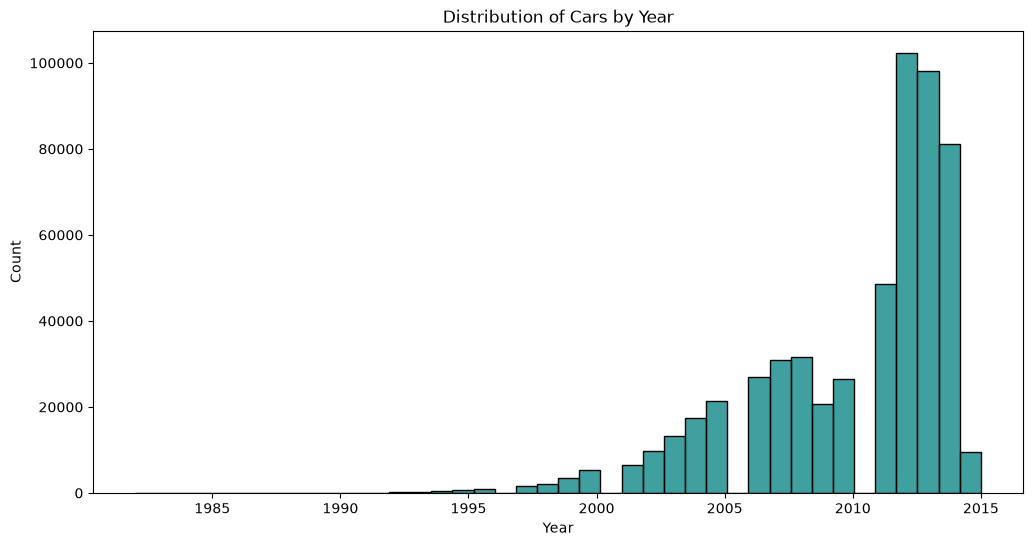

In [251]:
plt.figure(figsize=(12,6))
sns.histplot(x="Year", data=clean_df ,color="teal",bins=40)
plt.xlabel("Year")
plt.ylabel("Count")
plt.title("Distribution of Cars by Year")
plt.show()

In [252]:
clean_df

,Id,Year,Make,Model,Trim,Body,Transmission,VIN,State,ConditionValue,...,Interior,Seller,MMR,SellingPrice,SaleDate,SellingPrice_1_flag,Odometer_999999_flag,VehicleAge,PriceToMMR,PriceDifference
0,2,2015,Kia,Sorento,LX,Suv,automatic,5xyktca69fg566472,ca,5.0,...,Black,kia motors america inc,20500.0,21500.0,2014-12-16 04:30:00,False,False,0,1.048780,1000.0
1,3,2015,Kia,Sorento,LX,Suv,automatic,5xyktca69fg561319,ca,5.0,...,Beige,kia motors america inc,20800.0,21500.0,2014-12-16 04:30:00,False,False,0,1.033654,700.0
2,4,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,...,Black,financial services remarketing (lease),31900.0,30000.0,2015-01-14 20:30:00,False,False,1,0.940439,-1900.0
3,5,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,...,Black,volvo na rep/world omni,27500.0,27750.0,2015-01-28 20:30:00,False,False,0,1.009091,250.0
4,6,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,...,Black,financial services remarketing (lease),66000.0,67000.0,2014-12-18 04:30:00,False,False,1,1.015152,1000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
558832,558834,2015,Kia,K900,Luxury,Sedan,Unknown,knalw4d4xf6019304,in,45.0,...,Black,avis corporation,35300.0,33000.0,2015-07-09 00:00:00,False,False,0,0.934844,-2300.0
558833,558835,2012,Ram,2500,Power Wagon,Crew Cab,automatic,3c6td5et6cg112407,wa,5.0,...,Black,i -5 uhlmann rv,30200.0,30800.0,2015-07-08 02:30:00,False,False,3,1.019868,600.0
558834,558836,2012,BMW,X5,xDrive35d,Suv,automatic,5uxzw0c58cl668465,ca,48.0,...,Black,financial services remarketing (lease),29800.0,34000.0,2015-07-08 02:30:00,False,False,3,1.140940,4200.0
558835,558837,2015,Nissan,Altima,2.5 S,Sedan,automatic,1n4al3ap0fc216050,ga,38.0,...,Black,enterprise vehicle exchange / tra / rental / t...,15100.0,11100.0,2015-07-08 23:45:00,False,False,0,0.735099,-4000.0


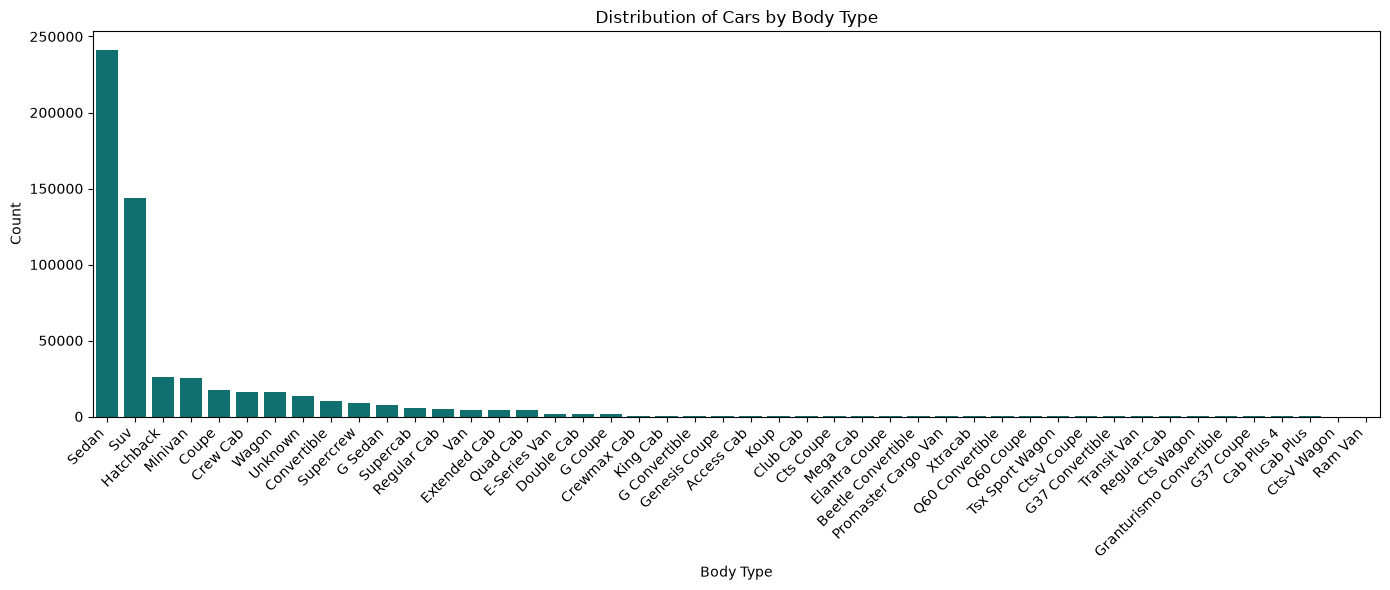

In [253]:
plt.figure(figsize=(14, 6))

sns.countplot(
    data=clean_df, 
    x="Body", 
    color="teal",
    order=clean_df["Body"].value_counts().index
)

plt.xticks(rotation=45, ha='right')
plt.xlabel("Body Type")
plt.ylabel("Count")
plt.title("Distribution of Cars by Body Type")
plt.tight_layout()

plt.show()

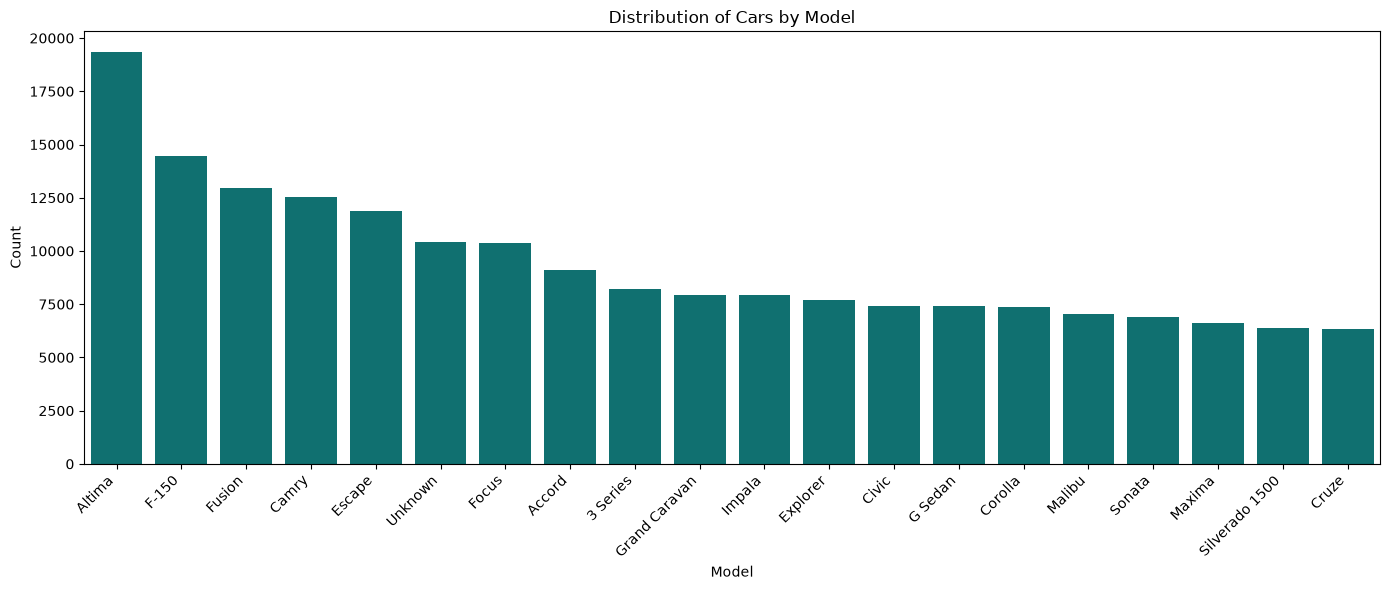

In [254]:
top_models = clean_df["Model"].value_counts().head(20)
plt.figure(figsize=(14, 6))

sns.countplot(
    data=clean_df, 
    x="Model", 
    color="teal",
    order=top_models.index
)

plt.xticks(rotation=45, ha='right')
plt.xlabel("Model")
plt.ylabel("Count")
plt.title("Distribution of Cars by Model")
plt.tight_layout()

plt.show()

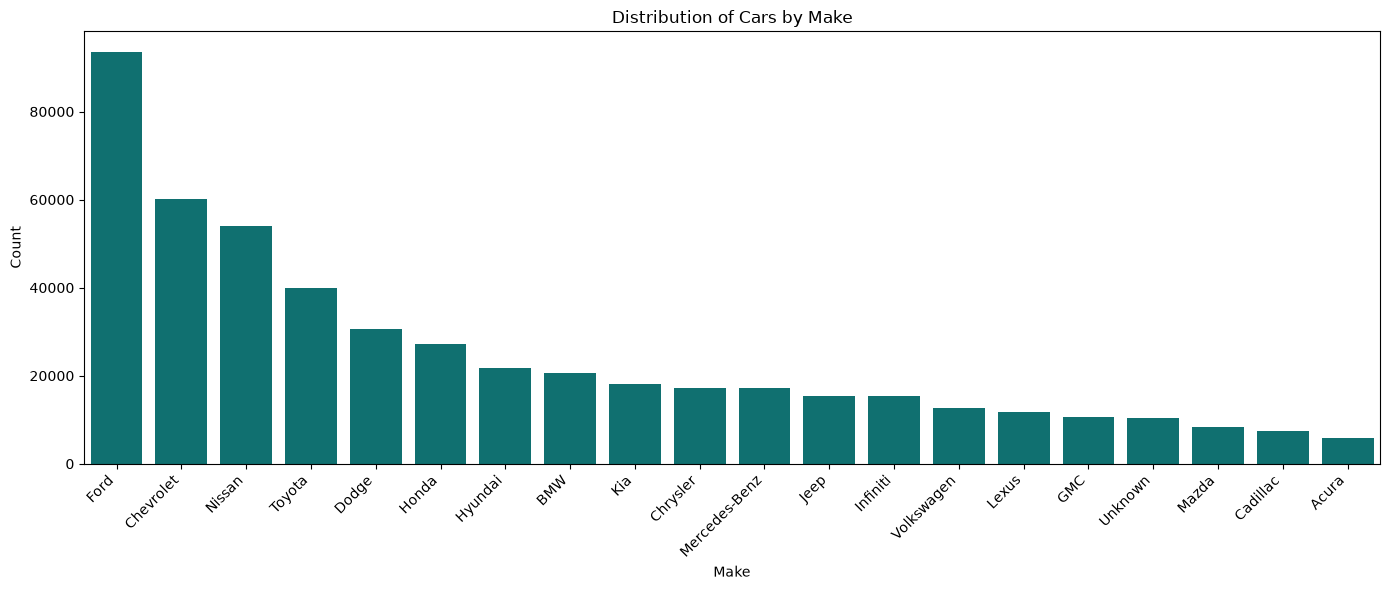

In [255]:
top_makes = clean_df["Make"].value_counts().head(20)
plt.figure(figsize=(14, 6))

sns.countplot(
    data=clean_df, 
    x="Make", 
    color="teal",
    order=top_makes.index
)

plt.xticks(rotation=45, ha='right')
plt.xlabel("Make")
plt.ylabel("Count")
plt.title("Distribution of Cars by Make")
plt.tight_layout()

plt.show()

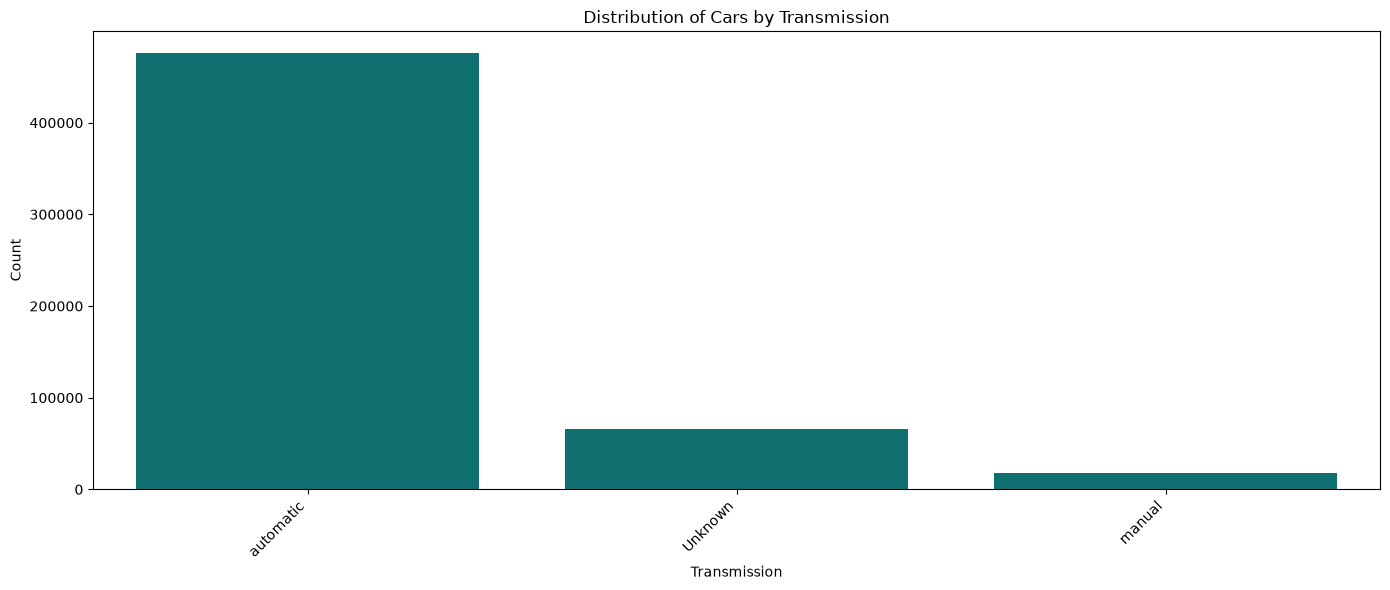

In [256]:
top_transmissions = clean_df["Transmission"].value_counts().head(20)
plt.figure(figsize=(14, 6))

sns.countplot(
    data=clean_df, 
    x="Transmission", 
    color="teal",
    order=top_transmissions.index
)

plt.xticks(rotation=45, ha='right')
plt.xlabel("Transmission")
plt.ylabel("Count")
plt.title("Distribution of Cars by Transmission")
plt.tight_layout()

plt.show()

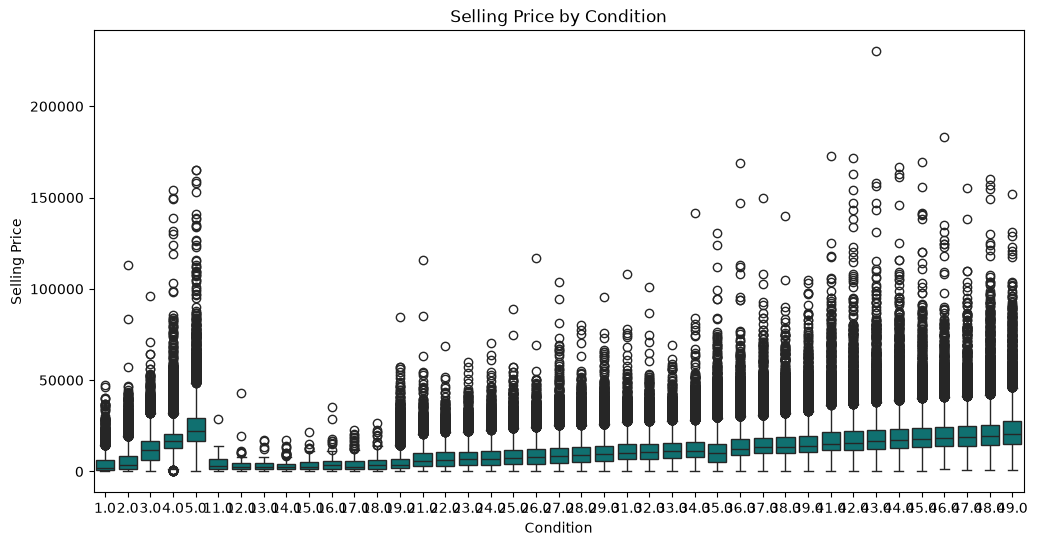

In [257]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=clean_df,
    x="ConditionValue",
    y="SellingPrice",
    color="teal"
)

plt.title("Selling Price by Condition")
plt.xlabel("Condition")
plt.ylabel("Selling Price")
plt.show()

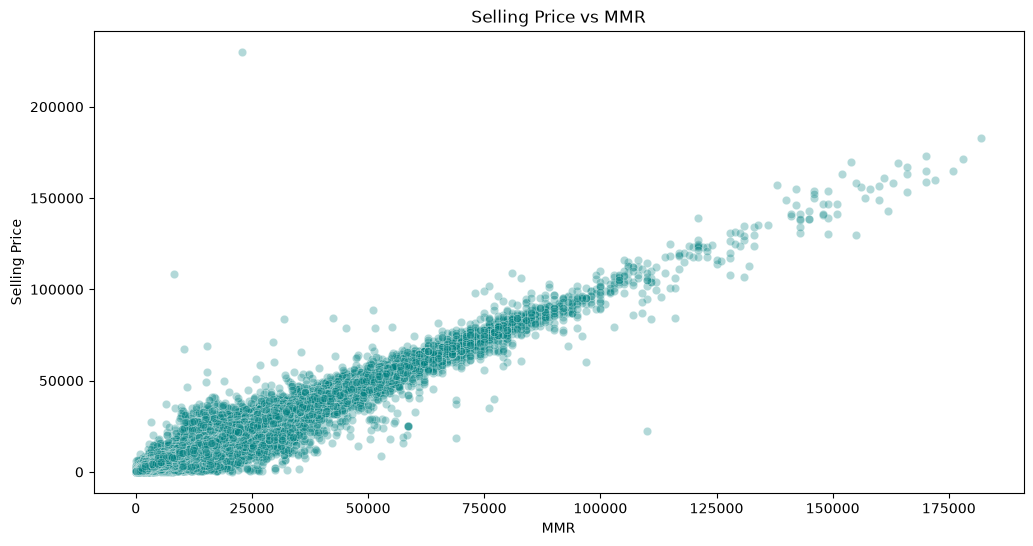

In [258]:
plt.figure(figsize=(12,6))

sns.scatterplot(
    data=clean_df,
    x="MMR",
    y="SellingPrice",
    alpha=0.3,
    color="teal"
)

plt.xlabel("MMR")
plt.ylabel("Selling Price")
plt.title("Selling Price vs MMR")

plt.show()

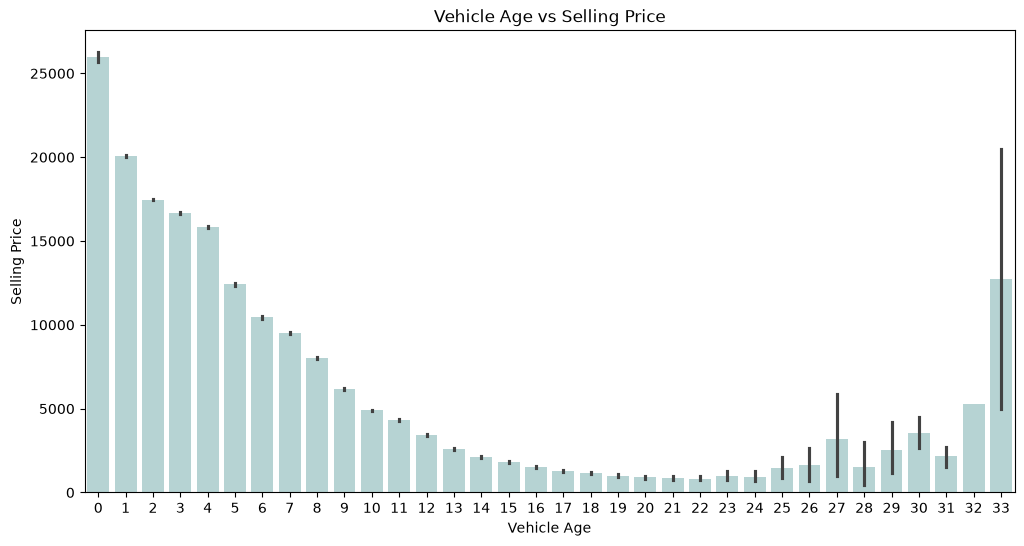

In [259]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=clean_df,
    x="VehicleAge",
    y="SellingPrice",
    alpha=0.3,
    color="teal"
)

plt.title("Vehicle Age vs Selling Price")
plt.xlabel("Vehicle Age")
plt.ylabel("Selling Price")
plt.show()

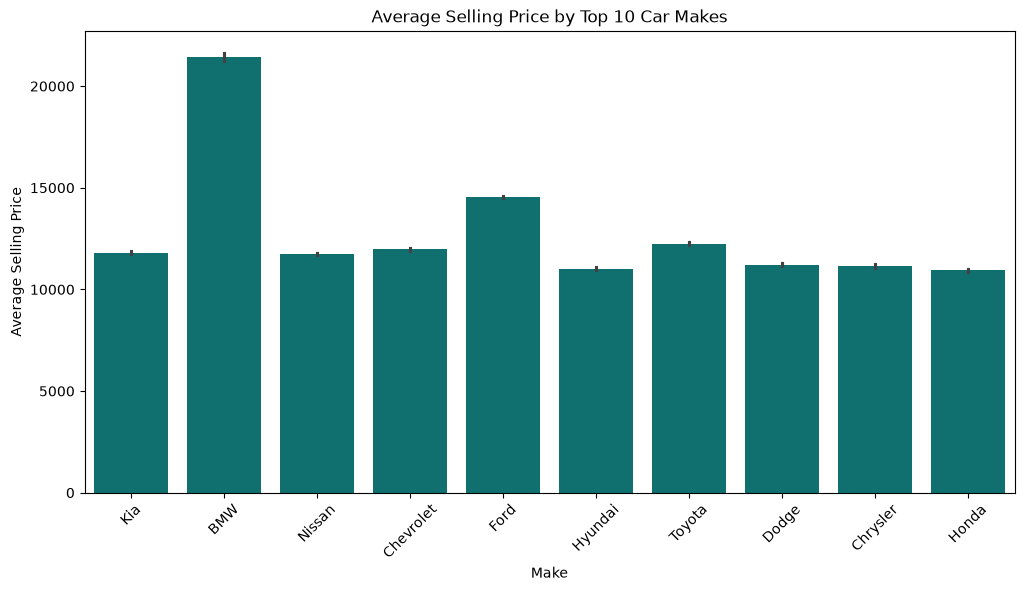

In [260]:
top_makes = clean_df["Make"].value_counts().head(10).index

plot_df = clean_df[clean_df["Make"].isin(top_makes)]

plt.figure(figsize=(12,6))

sns.barplot(
    data=plot_df,
    x="Make",
    y="SellingPrice",
    color="teal"
)

plt.title("Average Selling Price by Top 10 Car Makes")
plt.xlabel("Make")
plt.ylabel("Average Selling Price")
plt.xticks(rotation=45)
plt.show()

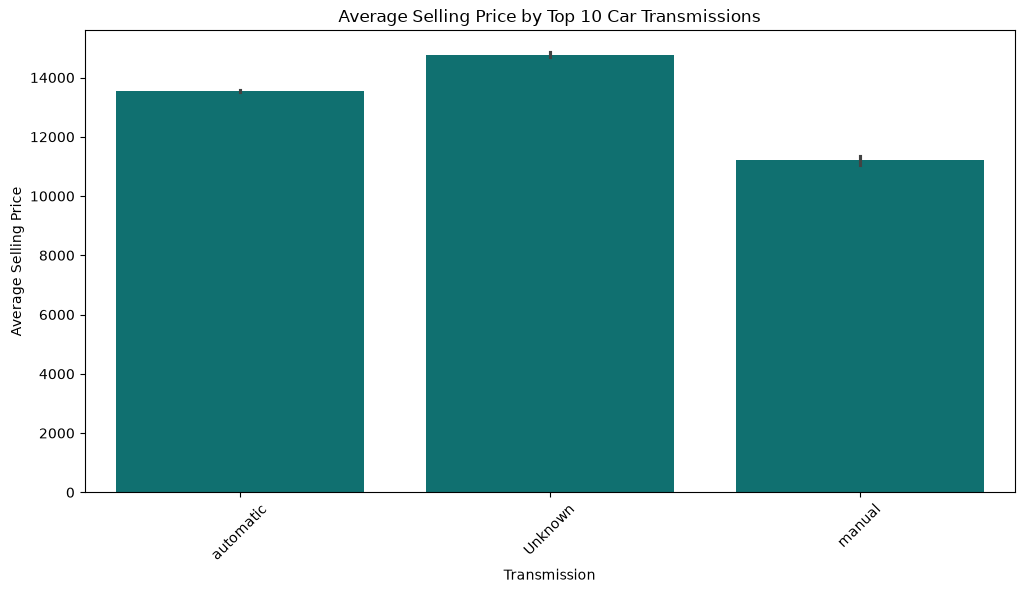

In [261]:
top_transmissions = clean_df["Transmission"].value_counts().head(10).index

plot_df = clean_df[clean_df["Transmission"].isin(top_transmissions)]

plt.figure(figsize=(12,6))

sns.barplot(
    data=plot_df,
    x="Transmission",
    y="SellingPrice",
    color="teal"
)

plt.title("Average Selling Price by Top 10 Car Transmissions")
plt.xlabel("Transmission")
plt.ylabel("Average Selling Price")
plt.xticks(rotation=45)
plt.show()

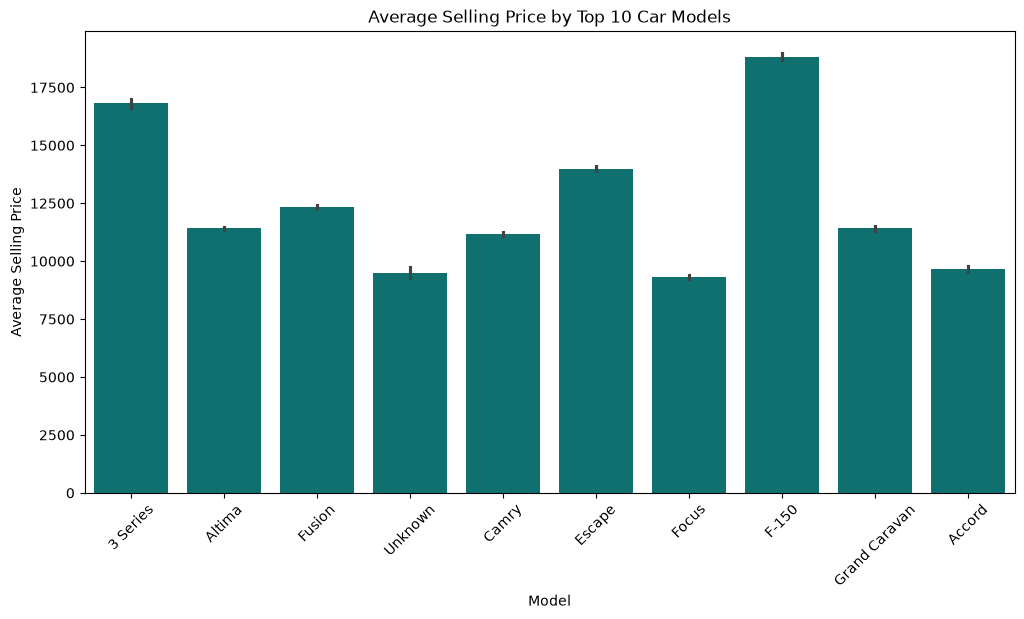

In [262]:
top_models = clean_df["Model"].value_counts().head(10).index

plot_df = clean_df[clean_df["Model"].isin(top_models)]

plt.figure(figsize=(12,6))

sns.barplot(
    data=plot_df,
    x="Model",
    y="SellingPrice",
    color="teal"
)

plt.title("Average Selling Price by Top 10 Car Models")
plt.xlabel("Model")
plt.ylabel("Average Selling Price")
plt.xticks(rotation=45)
plt.show()

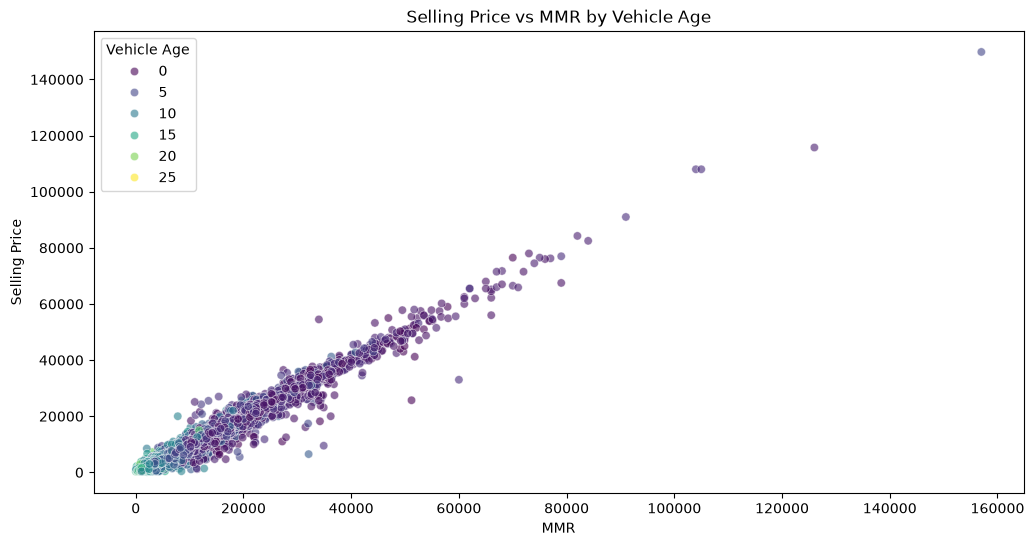

In [263]:
plt.figure(figsize=(12,6))

sns.scatterplot(
    data=clean_df.sample(10000),
    x="MMR",
    y="SellingPrice",
    hue="VehicleAge",
    palette="viridis",
    alpha=0.6
)

plt.title("Selling Price vs MMR by Vehicle Age")
plt.xlabel("MMR")
plt.ylabel("Selling Price")
plt.legend(title="Vehicle Age")
plt.show()

In [265]:
clean_df.to_excel("cleaned_car_sales.xlsx", index=False)